# Human Serum aggregation

Read the source protocol CSVs for one condition and write its compact, deduplicated union.

In [1]:
CONDITION="human_serum"
WRITE_EXPORTS=True
NOTEBOOK_ID="aggregation_human_serum"
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "src/pep_compass").is_dir())
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
from proteolysis_data_manager.protocols.half_life.filtering import load_half_life_data, prepare_protocol, export_protocol
from proteolysis_data_manager.integration.half_life.schema import CLEAN_COLUMNS, source_mask, row_key, typed
from proteolysis_data_manager.analysis.half_life.visualization import (formatted_table, duration_summary, plot_duration_distributions,
    plot_acceptance_conditions, plot_before_after, readable_time_axis, time_bins, DURATION_COLORS, DURATION_LABELS)
DATA_ROOT = ROOT / "data/half_time_datasets"
SERIES = ROOT / "assets/experiments/analysis/09_26/20_serum_proteolysis_calibration_max/notebooks/0_data_analysis_half_life"
RESULTS = SERIES.parents[1] / "results/0_data_analysis_half_life" / CONDITION / NOTEBOOK_ID
if WRITE_EXPORTS: RESULTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi":110, "axes.spines.top":False, "axes.spines.right":False, "axes.grid":True, "grid.alpha":.12})
def table(frame):
    if len(frame)>30: display(HTML(f"<p>Preview: 30 of {len(frame)} rows.</p>"))
    display(HTML(formatted_table(frame, limit=30)))
def figure(fig, name):
    if WRITE_EXPORTS: fig.savefig(RESULTS / name, bbox_inches="tight")
    plt.show(); plt.close(fig)
def counts(frame):
    point=frame.half_life_seconds.notna()
    return {"observations":len(frame), "sequences":frame.sequence.nunique(), "numeric":int(point.sum()),
            "class_only":int((~point & frame.half_life_class.notna()).sum()),
            "unresolved":int((~point & frame.half_life_class.isna()).sum())}

from proteolysis_data_manager.integration.half_life.aggregation import aggregate_environment, source_accounting
SOURCES=["peplife2","plifepred","dramp","pepmsnd","cavaco"]


## Inputs and verified measurement identity

Central manifests verify input CSVs and their shared normalization/protocol policy. A shared source reference plus identical scientific fields establishes a repeated normalized measurement. Equal sequences or equal half-lives alone do not. Missing fields were already enriched during normalization, and the complete source/ID lists survive final aggregation.

No wide provenance columns or report files are added. Conflicting measurements remain separate; their explanations are in `normalized/remarks_<source>.md`.

In [2]:
if not WRITE_EXPORTS:
    raise RuntimeError("Template export disabled. Copy into a condition folder and enable WRITE_EXPORTS.")
before, after, lineage, possible, manifest = aggregate_environment(DATA_ROOT, CONDITION, SOURCES)
table(pd.DataFrame(manifest["inputs"]))
table(pd.DataFrame([{"condition":CONDITION,"source_input_rows":len(before),"final_measurements":len(after),"repeated_input_rows_merged":len(before)-len(after),**counts(after),"reported_ci95":int(after.ci_level.eq(.95).sum()),"unconfirmed_coincident_points":len(possible)}]))

source,csv,sha256,source_rows
peplife2,processed/human_serum/sources/peplife2.csv,48e95c3b5436906f68d5f3c723717aa17577158c03fdda289f8300e1745492e8,102
plifepred,processed/human_serum/sources/plifepred.csv,06cfe1be25348b01c7add0a21ff1137836bf109f0a77bddb01449ed72ec8999a,11
dramp,processed/human_serum/sources/dramp.csv,9ff7fd35bb663df953594ab6b27cd3d3897e383076837d87d53d6868bdfa4224,8
pepmsnd,processed/human_serum/sources/pepmsnd.csv,0b9eb8009e26adf35fa33abaf030ebd3e9a307f505f7a7dde9fc34dba0b5482c,74
cavaco,processed/human_serum/sources/cavaco.csv,f28e994ae74ceffba277c330c95f86bbd52e391e6b22523482e74e67bf777d1d,16


condition,source_input_rows,final_measurements,repeated_input_rows_merged,observations,sequences,numeric,class_only,unresolved,reported_ci95,unconfirmed_coincident_points
human_serum,211,206,5,206,104,171,9,26,16,40


## Source coverage, label availability and PEPlife2 overlap

Raw source representations and normalized measurements have different denominators: normalization merges verified repeated source rows. The next reduction selects species/matrix and the explicit assay mode, then applies pH/temperature gates. Tables account for each reduction.

Every retained row belongs to one label group: numerical, class-only, or unresolved. Missing half-life does not remove it. Shared sequences and verified shared measurements with PEPlife2 are reported separately; sequence overlap is not deduplication evidence.

coverage


source,raw_source_representations,normalized_measurements,condition_records,selected_assay_mode,other_known_mode,unknown_assay_mode,outside_ph_temperature,exported_source_records
peplife2,4500,4366,157,103,54,0,1,102
plifepred,424,261,16,12,4,0,1,11
dramp,111,111,28,8,0,20,0,8
pepmsnd,635,635,80,74,6,0,0,74
cavaco,16,16,16,16,0,0,0,16


label_types


source,exported_records,numeric,class_only,unresolved,without_numeric_half_life
peplife2,102,75,6,21,27
plifepred,11,11,0,0,0
dramp,8,0,3,5,8
pepmsnd,74,74,0,0,0
cavaco,16,16,0,0,0


peplife2_overlap


source,comparison,shared_sequences,shared_sequence_records,verified_same_measurements,new_sequences
peplife2,reference,60,102,None,0
plifepred,against PEPlife2,7,11,5,0
dramp,against PEPlife2,3,8,0,0
pepmsnd,against PEPlife2,26,30,0,44
cavaco,against PEPlife2,0,0,0,16


source,parameter,cavaco,dramp,peplife2,pepmsnd,plifepred
,ci_level,0,8,102,74,11
,ci_lower_seconds,0,8,102,74,11
,ci_upper_seconds,0,8,102,74,11
,half_life_class,0,5,21,0,0
,half_life_seconds,0,8,27,0,0
,matrix_fraction,0,8,100,74,11
,peptide_concentration_um,0,8,34,74,3
,ph,16,8,102,74,11
,replicate_count,0,8,102,74,11
,sd_seconds,16,8,102,74,11


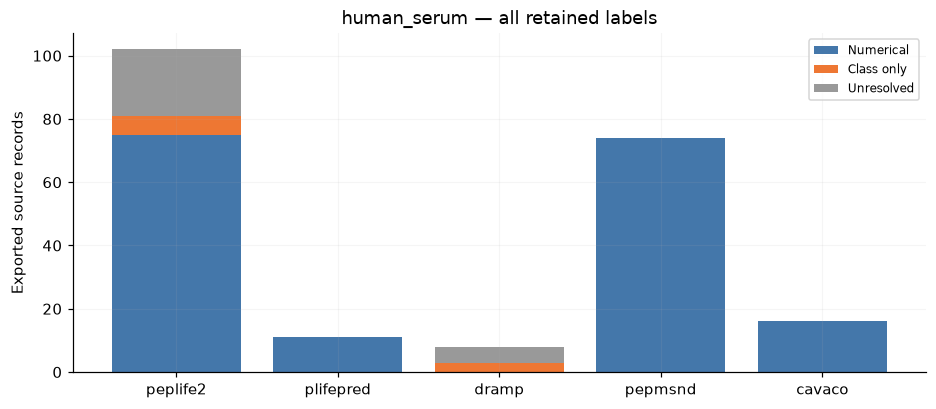

In [3]:
inventory=load_half_life_data(DATA_ROOT)
accounting=source_accounting(DATA_ROOT,inventory,before,after,manifest["configuration"],SOURCES)
for name in ["coverage","label_types","peplife2_overlap"]:
    print(name); table(accounting[name])
table(accounting["missingness"].pivot(index="parameter",columns="source",values="missing").reset_index())
labels=accounting["label_types"].set_index("source")
fig,ax=plt.subplots(figsize=(10,4)); bottom=pd.Series(0,index=labels.index)
for field,color,label in [("numeric","#4477AA","Numerical"),("class_only","#EE7733","Class only"),("unresolved","#999999","Unresolved")]:
    ax.bar(labels.index,labels[field],bottom=bottom,color=color,label=label);bottom+=labels[field]
ax.set(ylabel="Exported source records",title=CONDITION+" — all retained labels");ax.legend(fontsize=8)
figure(fig,"source_label_availability.png")
for _,r in accounting["label_types"].iterrows():
    assert r.numeric+r.class_only+r.unresolved==r.exported_records
for _,r in accounting["coverage"].iterrows():
    assert r.condition_records==r.selected_assay_mode+r.other_known_mode+r.unknown_assay_mode
    assert r.selected_assay_mode==r.outside_ph_temperature+r.exported_source_records

## Duration classes, distributions and missingness

**short** <30 min (blue); **medium** 30 min–6 h inclusive (orange); **long** >6 h (green); unresolved (gray). All numerical and class-only observations enter class counts. Numerical histograms use reported points or the explicitly documented CI-midpoint exception only.

Before/after counts here describe merging source copies of shared observations, not filtering out class-only data.

duration_class,time_interval,all_assigned_records,exact_point_records,bounded_or_non_numeric_records,stage
unresolved,no unique interval,26,0,26,Source CSV inputs
short,<30 min,43,35,8,Source CSV inputs
medium,30 min–6 h,76,76,0,Source CSV inputs
long,>6 h,66,65,1,Source CSV inputs
unresolved,no unique interval,26,0,26,Deduplicated union
short,<30 min,43,35,8,Deduplicated union
medium,30 min–6 h,73,73,0,Deduplicated union
long,>6 h,64,63,1,Deduplicated union


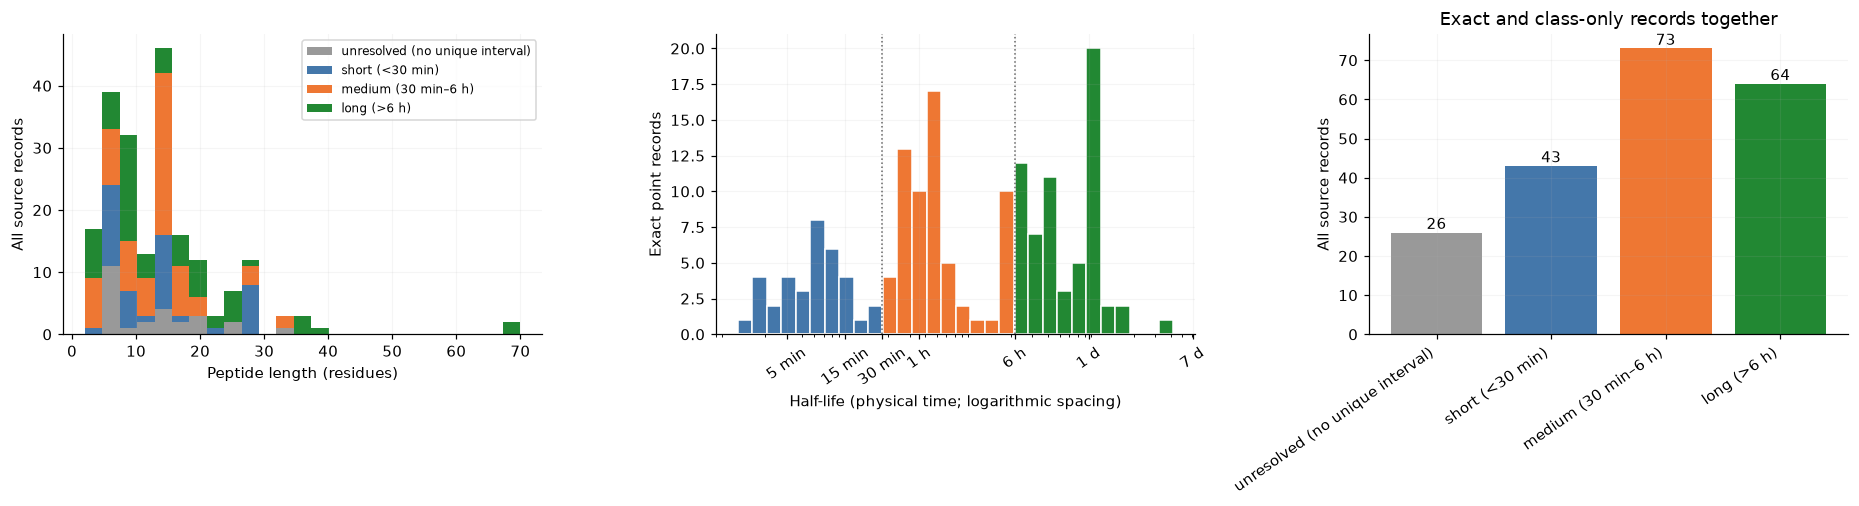

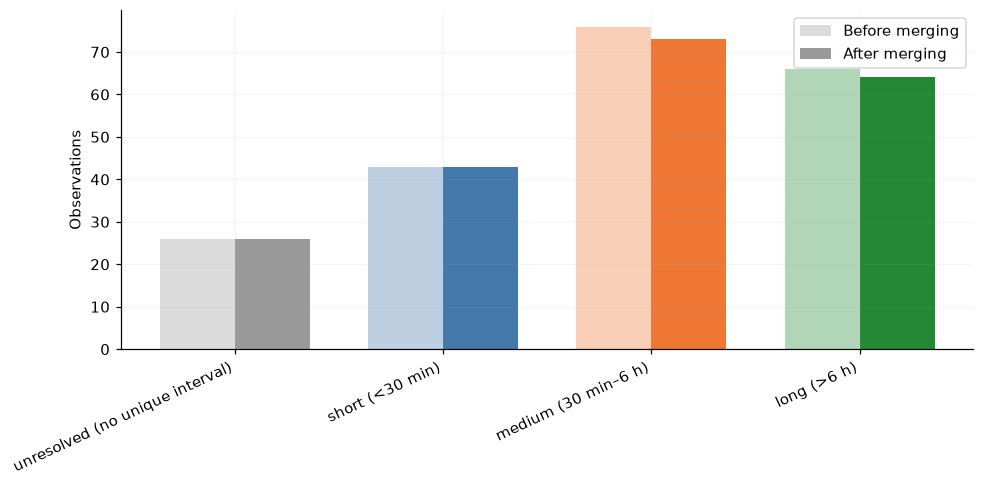

field,missing,denominator
sequence,0,206
sequence_length,0,206
chirality,74,206
topology,0,206
n_terminal_modification,4,206
c_terminal_modification,4,206
other_modifications,0,206
species,0,206
matrix,0,206
matrix_fraction,188,206


normalized_row_key,source,id
aaee02447d9c19d222cf6e23ba0c93f11c39bbd9a4420e161148fa78046931d3,peplife2,all:1001
aaee02447d9c19d222cf6e23ba0c93f11c39bbd9a4420e161148fa78046931d3,peplife2,all:1002
aaee02447d9c19d222cf6e23ba0c93f11c39bbd9a4420e161148fa78046931d3,peplife2,all:1003
3be533321fa88df8625366d6ab0d77098d9dfc004d652c991290e330ec8200d5,peplife2,all:1004
3be533321fa88df8625366d6ab0d77098d9dfc004d652c991290e330ec8200d5,peplife2,all:1005
3be533321fa88df8625366d6ab0d77098d9dfc004d652c991290e330ec8200d5,peplife2,all:1006
0c8f99233ac5061103a935375de5f0ba52484c54b466cf9cb0b3c9bc79db82e1,peplife2,all:1007
0c8f99233ac5061103a935375de5f0ba52484c54b466cf9cb0b3c9bc79db82e1,peplife2,all:1008
0c8f99233ac5061103a935375de5f0ba52484c54b466cf9cb0b3c9bc79db82e1,peplife2,all:1009
a278ef5ea20b9c5309c55c081cfba6c362aa6a0bc1336914c51438b5893b2d48,peplife2,all:1010


source,source_record_id,sequence,sequence_length,chirality,topology,n_terminal_modification,c_terminal_modification,other_modifications,species,matrix,matrix_fraction,temperature_c,ph,peptide_concentration_um,half_life_seconds,sd_seconds,ci_lower_seconds,ci_upper_seconds,ci_level,replicate_count,half_life_class,in_vivo_in_vitro
"[peplife2, plifepred]","[{'id': 'all:1034', 'source': 'peplife2'}, {'id': 'all:1035', 'source': 'peplife2'}, {'id': 'all:1036', 'source': 'peplife2'}, {'id': 'mixed:1036', 'source': 'plifepred'}]",CRRWWRFC,8,l,cyclic (c1-c8),free,amidation,free,human,serum,<NA>,<NA>,<NA>,5,2.34e+04,<NA>,<NA>,<NA>,<NA>,<NA>,long,in vitro
"[peplife2, plifepred]","[{'id': 'all:1040', 'source': 'peplife2'}, {'id': 'all:1041', 'source': 'peplife2'}, {'id': 'all:1042', 'source': 'peplife2'}, {'id': 'mixed:1042', 'source': 'plifepred'}]",CRRWWRFC,8,l,cyclic (c1-c8),acetylation,amidation,free,human,serum,<NA>,<NA>,<NA>,5,2.34e+04,<NA>,<NA>,<NA>,<NA>,<NA>,long,in vitro
"[peplife2, plifepred]","[{'id': 'all:1994', 'source': 'peplife2'}, {'id': 'mixed:1994', 'source': 'plifepred'}, {'id': 'natural:1994', 'source': 'plifepred'}]",LEQYANQLADQIIKEATE,18,l,linear,free,free,free,human,serum,<NA>,<NA>,<NA>,<NA>,5400,<NA>,<NA>,<NA>,<NA>,<NA>,medium,in vitro
[peplife2],"[{'id': 'all:2084', 'source': 'peplife2'}]",EAAGIGILTV,10,l,linear,free,free,free,human,serum,<NA>,<NA>,<NA>,0.025,2700,<NA>,<NA>,<NA>,<NA>,<NA>,medium,in vitro
[peplife2],"[{'id': 'all:2266', 'source': 'peplife2'}]",GPETLCGAELVDALQFVCGDRGFYFNKPTGYGYGSSRRAPQTGIVDECCFRSCDLRRLMYCAPLKPAKSA,70,l,linear,free,free,free,human,serum,<NA>,<NA>,<NA>,<NA>,7.2e+04,<NA>,<NA>,<NA>,<NA>,<NA>,long,in vitro
[peplife2],"[{'id': 'all:4218', 'source': 'peplife2'}]",VIKLSGRELVRAQIAISGMSTWSKRSL,27,l,linear,free,free,free,human,serum,<NA>,<NA>,<NA>,<NA>,360,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:4919', 'source': 'peplife2'}]",YHPYKEIEQLIELANYQVLS,20,l,linear,free,free,free,human,serum,<NA>,<NA>,<NA>,300,3096,<NA>,<NA>,<NA>,<NA>,<NA>,medium,in vitro
[peplife2],"[{'id': 'all:5203', 'source': 'peplife2'}]",CNCKAPETARCAIRCVIFTSGGSRW,25,l,"cyclic (c1-c11, c3-c15)",free,free,free,human,serum,<NA>,<NA>,<NA>,<NA>,4.608e+04,<NA>,<NA>,<NA>,<NA>,<NA>,long,in vitro
[peplife2],"[{'id': 'all:5318', 'source': 'peplife2'}]",RLYE,4,mix,linear,l-arg replaced with d-arg at position 1,free,free,human,serum,<NA>,37,<NA>,<NA>,2.52e+04,<NA>,<NA>,<NA>,<NA>,<NA>,long,in vitro
[peplife2],"[{'id': 'all:2086', 'source': 'peplife2'}]",ELAGIGILTV,10,l,linear,free,free,methylation of nitrogen of amide bond b/w glu1 and leu2 (nme); methylation of carboxyl of leu8,human,serum,<NA>,<NA>,<NA>,0.025,8.64e+04,<NA>,<NA>,<NA>,<NA>,<NA>,long,in vitro


In [4]:
table(pd.concat([duration_summary(before).assign(stage="Source CSV inputs"),duration_summary(after).assign(stage="Deduplicated union")],ignore_index=True))
figure(plot_duration_distributions(after),"final_distributions.png")
summary_before=duration_summary(before);summary_after=duration_summary(after);x=np.arange(len(summary_after))
fig,ax=plt.subplots(figsize=(10,4))
colors=[DURATION_COLORS[c] for c in summary_after.duration_class]
ax.bar(x-.18,summary_before.all_assigned_records,width=.36,color=colors,alpha=.35,label="Before merging")
ax.bar(x+.18,summary_after.all_assigned_records,width=.36,color=colors,label="After merging")
ax.set_xticks(x,[DURATION_LABELS[c] for c in summary_after.duration_class],rotation=25,ha="right");ax.set(ylabel="Observations");ax.legend()
figure(fig,"before_after_classes.png")
table(pd.DataFrame([{"field":f,"missing":int(after[f].isna().sum()),"denominator":len(after)} for f in CLEAN_COLUMNS if f not in ["source","source_record_id"]]))
table(lineage);table(possible)
assert not after.apply(row_key,axis=1).duplicated().any()

## Final common CSV

The result uses the same 23 fields as normalization and source protocols. Select `half_life_seconds.notna()` for numerical analysis; select `half_life_seconds.isna() & half_life_class.notna()` for class-only validation. Both can use the duration class. Unresolved labels remain present with null values. Missing SD and CI stay null.

`source` is a list of all contributing bases; `source_record_id` is the full list of source-qualified references. In CSV these two fields are JSON; the library reader decodes them.

TODO (later analysis): estimate validation tolerances separately without changing reported CI.

In [5]:
table(pd.DataFrame({"column":CLEAN_COLUMNS}))
print("Final CSV:",DATA_ROOT/"processed"/CONDITION/(CONDITION+".csv"))

column
source
source_record_id
sequence
sequence_length
chirality
topology
n_terminal_modification
c_terminal_modification
other_modifications
species


Final CSV: /Users/max/Documents/repositories/pep-compass/data/half_time_datasets/processed/human_serum/human_serum.csv
